<a href="https://colab.research.google.com/github/anasarshad7677-netizen/Complete-ML-repo/blob/main/14_transformers_function_and_power_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [37]:
import pandas as pd
import numpy as np
import scipy.stats as stats
import seaborn as sns

import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.model_selection import cross_val_score


from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

from sklearn.preprocessing import FunctionTransformer
from sklearn.compose import ColumnTransformer

In [38]:
df = pd.read_csv('/content/train (2).csv',usecols=['Age','Fare','Survived'])
df.head(1)

,Survived,Age,Fare
0,0,22.0,7.25


In [39]:
df['Age'].fillna(df['Age'].mean(),inplace=True)


/tmp/ipykernel_611/1275544653.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['Age'].fillna(df['Age'].mean(),inplace=True)


In [40]:
df.isnull().sum()


,0
Survived,0
Age,0
Fare,0


In [41]:
x = df.iloc[:,1:3]
y = df.iloc[:,0]

In [42]:
x_train,x_test ,y_train,y_test = train_test_split(x,y,test_size=0.2,random_state=0)

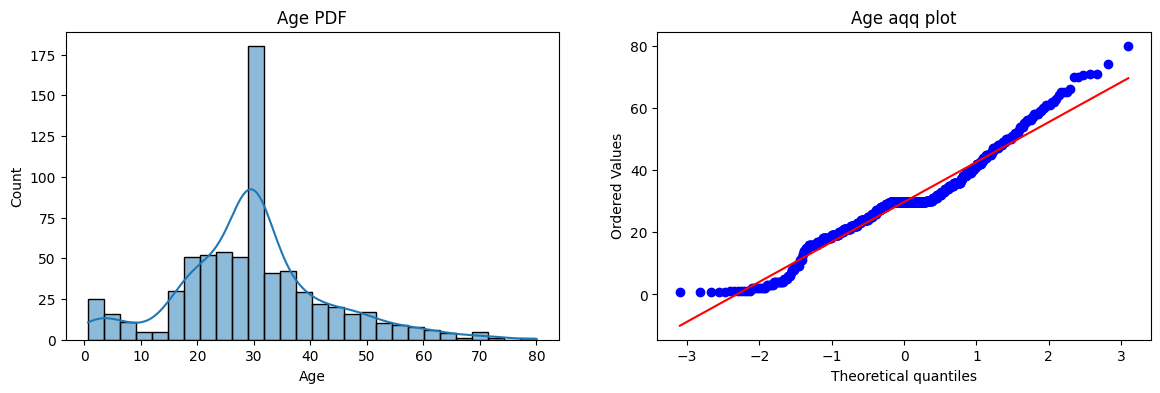

In [43]:
plt.figure(figsize=(14,4))
plt.subplot(121)
sns.histplot(x_train['Age'],kde=True)
plt.title('Age PDF')

plt.subplot(122)
stats.probplot(x_train['Age'],dist="norm",plot=plt )
plt.title('Age aqq plot')
plt.show()

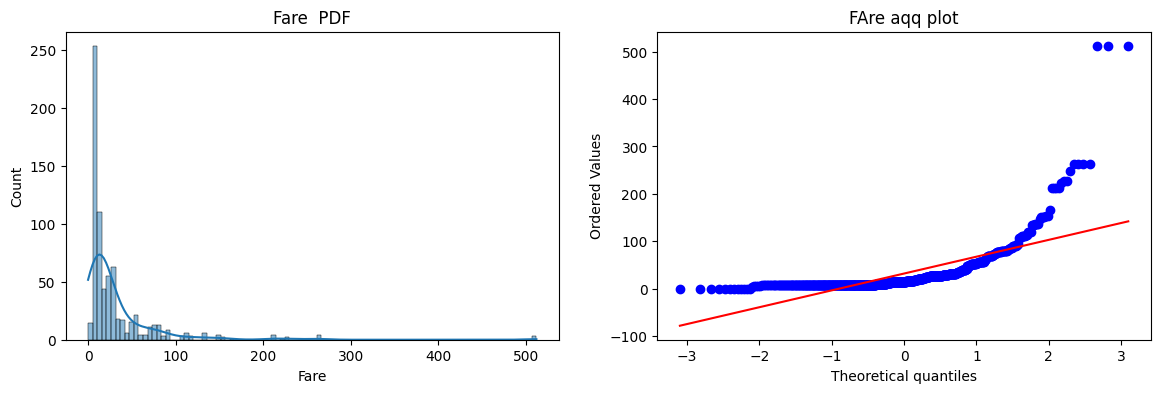

In [44]:
plt.figure(figsize=(14,4))
plt.subplot(121)
sns.histplot(x_train['Fare'],kde=True)
plt.title('Fare  PDF')

plt.subplot(122)
stats.probplot(x_train['Fare'],dist="norm",plot=plt )
plt.title('FAre aqq plot')
plt.show()

In [45]:
clf  = LogisticRegression()
clf2 = DecisionTreeClassifier()

In [46]:
clf.fit(x_train,y_train)
clf2.fit(x_train,y_train)

y_pred = clf.predict(x_test)
y_pred2 = clf2.predict(x_test)

print(accuracy_score(y_test,y_pred))
print(accuracy_score(y_test,y_pred2))


0.6983240223463687
0.6759776536312849


In [36]:
trf = FunctionTransformer(func=np.log1p)

In [48]:
x_train_transformed=trf.fit_transform(x_train)
x_test_transformed = trf.transform(x_test)

In [50]:
clf=LogisticRegression()
clf2=DecisionTreeClassifier()

clf.fit(x_train_transformed,y_train)
clf2.fit(x_train_transformed,y_train)

y_pred=clf.predict(x_test_transformed)
y_pred2=clf2.predict(x_test_transformed)

print(accuracy_score(y_test,y_pred))
print(accuracy_score(y_test,y_pred2))

0.7039106145251397
0.664804469273743


In [52]:
x_transformed = trf.fit_transform(x)
clf=LogisticRegression()
clf=DecisionTreeClassifier()
print(np.mean(cross_val_score(clf,x_transformed,y,scoring ='accuracy',cv=10)))
print(np.mean(cross_val_score(clf2,x_transformed,y,scoring='accuracy',cv=10)))

0.6689263420724095
0.6655805243445692


In [59]:
def apply_transform(transform):
    x = df.iloc[:, 1:3]
    y = df.iloc[:, 0]

    trf = ColumnTransformer([('log', FunctionTransformer(transform), ['Fare'])], remainder='passthrough')
    x_trans = trf.fit_transform(x)
    clf = LogisticRegression()

    print("accuracy", np.mean(cross_val_score(clf, x_trans, y, scoring='accuracy', cv=10)))

    plt.figure(figsize=(14, 4))

    plt.subplot(121)
    stats.probplot(x['Fare'], dist="norm", plot=plt)  # Fixed: using x['Fare']
    plt.title('Fare Q-Q Plot (Before)')

    plt.subplot(122)
    stats.probplot(x_trans[:, 0], dist="norm", plot=plt)  # Fixed: using index 0
    plt.title('Fare Q-Q Plot (After)')

    plt.show()

accuracy 0.6431335830212235


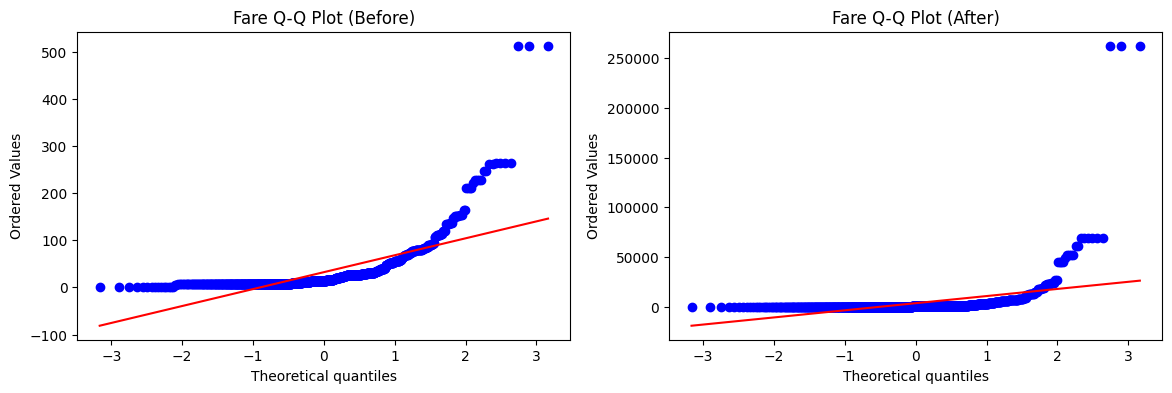

In [60]:
apply_transform(lambda x:x**2)